# Cardio AI — Exploratory Data Analysis

Exploratory notebook only. All production preprocessing, training, and
evaluation logic lives in `src/`, not here — this notebook re-uses those
modules (`src.data.validation`, `src.data.preprocessing`) rather than
duplicating logic, so EDA and the real pipeline can never drift apart.

**This is an educational/research dataset. Nothing here is a clinical finding.**

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt

from src.data.validation import validate_dataset
from src.data.preprocessing import CATEGORICAL_COLS, NUMERICAL_COLS

DATA_PATH = "../data/heart.csv"  # place your UCI-schema CSV here
df = pd.read_csv(DATA_PATH)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,54,0,0,137,429,0,2,171,1,4.4,0,1,3,0
1,45,1,3,116,400,0,2,195,0,1.9,0,4,2,1
2,56,0,2,188,359,0,1,139,1,3.9,1,2,2,1
3,46,1,0,192,500,0,2,95,0,4.3,1,1,3,0
4,42,1,3,117,485,0,2,177,1,0.4,1,2,1,1


## 1. Validate the raw dataset

Uses the exact same validation module the training pipeline uses.

In [2]:
result = validate_dataset(df)
print("Valid:", result.is_valid)
for e in result.errors:
    print("ERROR:", e)
for w in result.warnings:
    print("WARNING:", w)

Valid: True


## 2. Class balance

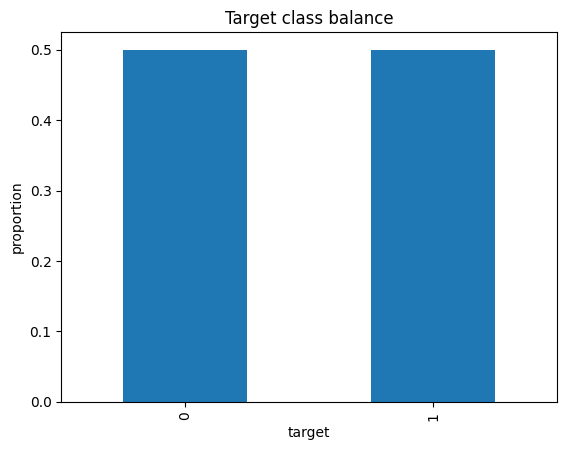

In [3]:
df["target"].value_counts(normalize=True).plot(kind="bar", title="Target class balance")
plt.xlabel("target"); plt.ylabel("proportion"); plt.show()

## 3. Numerical feature distributions

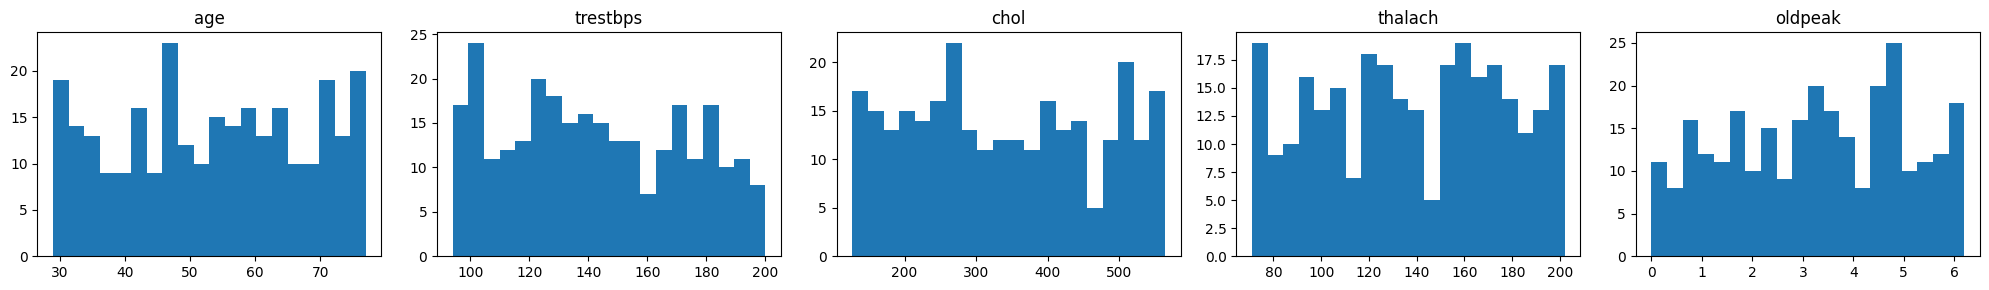

In [4]:
fig, axes = plt.subplots(1, len(NUMERICAL_COLS), figsize=(4 * len(NUMERICAL_COLS), 3))
for ax, col in zip(axes, NUMERICAL_COLS):
    ax.hist(df[col], bins=20)
    ax.set_title(col)
fig.tight_layout()
plt.show()

## 4. Categorical feature counts

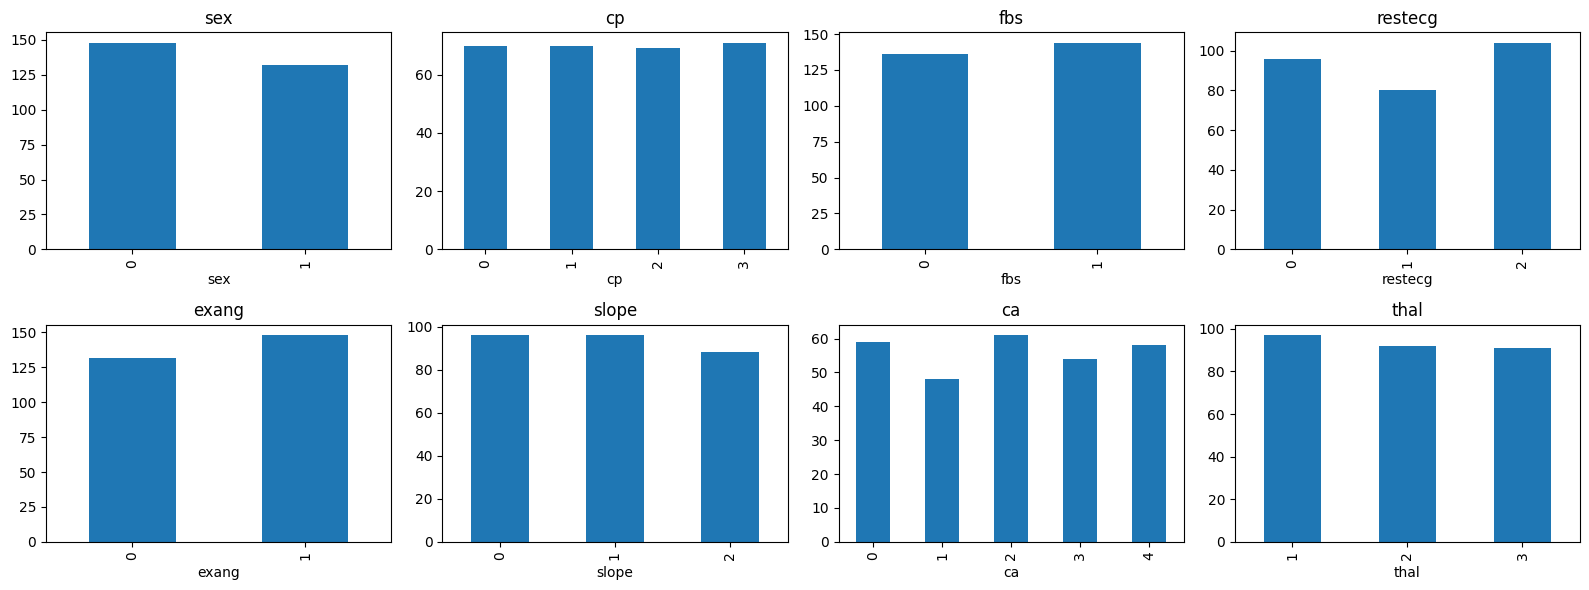

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), CATEGORICAL_COLS):
    df[col].value_counts().sort_index().plot(kind="bar", ax=ax, title=col)
fig.tight_layout()
plt.show()

## 5. Correlation among numerical features

Correlation, not causation — see the SHAP note in `src/explainability/shap_explainer.py`.

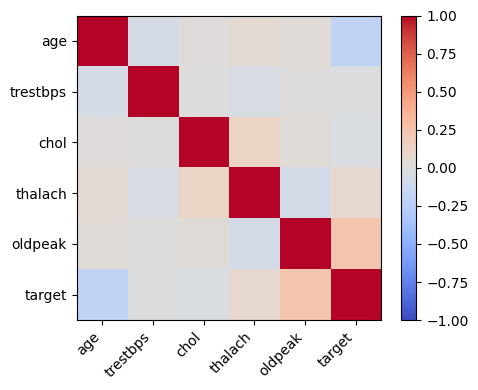

In [6]:
corr = df[NUMERICAL_COLS + ["target"]].corr()
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
fig.colorbar(im)
fig.tight_layout()
plt.show()

## Next steps

Run the actual training pipeline from the project root (not from this notebook):

```bash
python -m src.models.train --data data/heart.csv
```

This notebook is for exploration only — it never fits a preprocessing
pipeline or a model, to avoid having two different code paths that could
drift out of sync with `src/models/train.py`.